<a href="https://colab.research.google.com/github/mlopezmacho-EOI/proyecto-ventas/blob/firstBranch/ventas_colab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mi primer notebook en Colab: análisis de ventas

En este notebook vamos a petarlo, segundo cambio de prueba:
1. Comprobar el entorno en el que estamos trabajando
2. Generar un pequeño dataset de ventas
3. Explorarlo y calcular algunas métricas con pandas
4. Dibujar un gráfico
5. Guardar el resultado

Ejecuta cada celda con **Shift+Enter**.

## 1. Comprobar el entorno

In [ ]:
import sys
import pandas as pd
import numpy as np

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Python: 3.13.18
pandas: 2.2.3
numpy: 2.1.3


Los comandos de terminal funcionan con `!` delante:

In [ ]:
!ls -la

total 16
drwxr-xr-x 1 root root 4096 Oct 29 15:20 .
drwxr-xr-x 1 root root 4096 Nov  1 09:13 ..
drwxr-xr-x 4 root root 4096 Oct 29 15:20 .config
drwxr-xr-x 1 root root 4096 Oct 29 15:20 sample_data


## 2. Generar un dataset de ventas

Creamos 500 ventas inventadas de una cadena de cafeterías. Fijamos la semilla (`seed`) para que todos obtengamos los mismos datos.

In [ ]:
rng = np.random.default_rng(seed=42)
n = 500

precios = {"Café": 1.50, "Té": 1.80, "Zumo": 2.50, "Bocadillo": 4.00}

ventas = pd.DataFrame({
    "fecha": pd.to_datetime("2026-01-01") + pd.to_timedelta(rng.integers(0, 180, n), unit="D"),
    "tienda": rng.choice(["Madrid", "Barcelona", "A Coruña", "Sevilla"], n),
    "producto": rng.choice(list(precios), n, p=[0.4, 0.15, 0.2, 0.25]),
    "unidades": rng.integers(1, 6, n),
})
ventas["precio"] = ventas["producto"].map(precios)

ventas.head()

,fecha,tienda,producto,unidades,precio
0,2026-01-17,Madrid,Zumo,5,2.5
1,2026-05-20,A Coruña,Bocadillo,1,4.0
2,2026-04-28,Sevilla,Bocadillo,2,4.0
3,2026-03-20,Sevilla,Té,3,1.8
4,2026-03-19,Barcelona,Té,4,1.8


## 3. Explorar los datos

In [ ]:
print("Filas y columnas:", ventas.shape)
ventas.dtypes

Filas y columnas: (500, 5)


,0
fecha,datetime64[ns]
tienda,object
producto,object
unidades,int64
precio,float64


In [ ]:
ventas.describe()

,fecha,unidades,precio
count,500,500.000000,500.000000
mean,2026-03-31 08:15:21.600000,2.960000,2.386200
min,2026-01-01 00:00:00,1.000000,1.500000
25%,2026-02-17 00:00:00,2.000000,1.500000
50%,2026-03-30 12:00:00,3.000000,1.800000
75%,2026-05-15 06:00:00,4.000000,4.000000
max,2026-06-29 00:00:00,5.000000,4.000000
std,NaN,1.397966,1.034529


¿Cuántas veces se ha vendido cada producto? Es lo mismo que hacíamos en la terminal con `sort | uniq -c`:

In [ ]:
ventas["producto"].value_counts()

,count
producto,
Café,206
Bocadillo,133
Zumo,89
Té,72


Calculamos el importe de cada venta. Fíjate en que no hay ningún bucle `for`: la operación es **vectorizada** y la ejecuta numpy por dentro, en código compilado.

In [ ]:
ventas["importe"] = ventas["unidades"] * ventas["precio"]
ventas.head()

,fecha,tienda,producto,unidades,precio,importe
0,2026-01-17,Madrid,Zumo,5,2.5,12.5
1,2026-05-20,A Coruña,Bocadillo,1,4.0,4.0
2,2026-04-28,Sevilla,Bocadillo,2,4.0,8.0
3,2026-03-20,Sevilla,Té,3,1.8,5.4
4,2026-03-19,Barcelona,Té,4,1.8,7.2


Facturación por tienda, de mayor a menor:

In [ ]:
por_tienda = (
    ventas.groupby("tienda")["importe"]
    .sum()
    .sort_values(ascending=False)
    .round(2)
)
por_tienda

,importe
tienda,
A Coruña,1088.1
Madrid,908.1
Sevilla,856.0
Barcelona,708.7


## 4. Un gráfico: facturación mensual por tienda

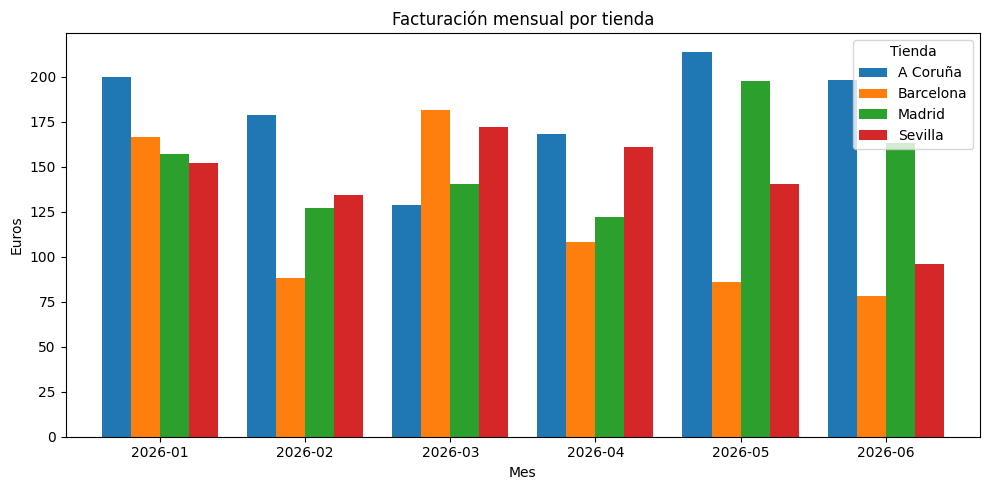

In [ ]:
import matplotlib.pyplot as plt

mensual = (
    ventas.assign(mes=ventas["fecha"].dt.to_period("M"))
    .pivot_table(index="mes", columns="tienda", values="importe", aggfunc="sum")
)

ax = mensual.plot(kind="bar", figsize=(10, 5), width=0.8)
ax.set_title("Facturación mensual por tienda")
ax.set_xlabel("Mes")
ax.set_ylabel("Euros")
ax.legend(title="Tienda")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Guardar el resultado

El archivo se guarda en el disco de la sesión y **se borra al cerrarla**. Lo verás en el panel de la carpeta, a la izquierda, y desde ahí puedes descargarlo.

In [ ]:
ventas.to_csv("ventas.csv", index=False)
print("Guardado ventas.csv")

Guardado ventas.csv


Para que no se pierda, guárdalo en tu Drive. La primera vez, Colab te pedirá permiso para acceder a él.

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ventas.to_csv("/content/drive/MyDrive/ventas.csv", index=False)
    print("Guardado en tu Drive: MyDrive/ventas.csv")
except ImportError:
    print("No estás en Colab: esta celda solo funciona allí")

Mounted at /content/drive
Guardado en tu Drive: MyDrive/ventas.csv


## Ejercicio

1. ¿Qué producto factura más en total? Pista: igual que `por_tienda`, pero agrupando por `"producto"`.
2. ¿Qué día de la semana se vende más? Pista: `ventas["fecha"].dt.day_name()`.
3. Añade una celda de texto con tus conclusiones.

Ejercicio 1.

In [ ]:
por_producto = (
    ventas.groupby("producto")["importe"]
    .sum()
    .sort_values(ascending=False)
    .round(2)
)
por_producto

,importe
producto,
Bocadillo,1596.0
Café,888.0
Zumo,702.5
Té,374.4


Ejercicio 2.

,importe
dia_semana,
Thursday,630.1
Friday,578.7
Saturday,512.5
Sunday,499.6
Wednesday,458.9
Tuesday,454.3
Monday,426.8
